In [2]:
!pip install xgboost lightgbm scikit-learn

  Using cached xgboost-3.1.2-py3-none-win_amd64.whl.metadata (2.1 kB)
  Using cached lightgbm-4.6.0-py3-none-win_amd64.whl.metadata (17 kB)
   ---------------------------------------- 0.0/72.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/72.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/72.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/72.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/72.0 MB 1.5 MB/s eta 0:00:49
    --------------------------------------- 1.3/72.0 MB 2.3 MB/s eta 0:00:32
   - -------------------------------------- 2.4/72.0 MB 3.2 MB/s eta 0:00:23
   - -------------------------------------- 3.1/72.0 MB 3.4 MB/s eta 0:00:21
   -- ------------------------------------- 3.9/72.0 MB 3.4 MB/s eta 0:00:21
   -- ------------------------------------- 4.5/72.0 MB 3.3 MB/s eta 0:00:21
   -- ------------------------------------- 4.5/72.0 MB 3.3 MB/s eta 0:00:21
   -- -----------------------------------

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("training_dataset_selected_features.csv")

In [5]:
df.head()

,MonthlyPersonalIncome,HighestEducation,AgeGroup,Q6_Transparency,Q8_Understanding,Q11_MaterialsAdequate,Q13_ViolenceCommon,Q14_OfficersInfluence,Q17_VoteForState,Q18_VoteForFriend,...,Q23_ReceivedGifts,Q25_PeopleSellVotes,Q28_VoteForFinancialAssistance,Q29_LackAccountabilityEncouragesVoteSelling,Q33_GiftsMoreLikelyWin,Q34_PeopleNoTrustElections,Zone_South South,EmploymentStatus_Part-time,EmploymentStatus_Retired,Target
0,0,2,1,2,2,2,3,2,3,4,...,0,3,5,2,3,3,0,0,0,0
1,3,2,4,1,2,3,3,2,3,3,...,0,2,4,3,2,2,0,0,0,0
2,3,0,2,1,1,2,2,3,2,2,...,0,2,2,3,3,4,0,0,0,1
3,0,5,1,2,3,4,2,3,2,1,...,0,2,4,3,2,3,0,0,0,0
4,2,1,0,2,2,2,2,2,2,2,...,0,3,3,5,2,3,0,0,0,0


In [6]:
df.shape

(444, 23)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 444 entries, 0 to 443
Data columns (total 23 columns):
 #   Column                                       Non-Null Count  Dtype
---  ------                                       --------------  -----
 0   MonthlyPersonalIncome                        444 non-null    int64
 1   HighestEducation                             444 non-null    int64
 2   AgeGroup                                     444 non-null    int64
 3   Q6_Transparency                              444 non-null    int64
 4   Q8_Understanding                             444 non-null    int64
 5   Q11_MaterialsAdequate                        444 non-null    int64
 6   Q13_ViolenceCommon                           444 non-null    int64
 7   Q14_OfficersInfluence                        444 non-null    int64
 8   Q17_VoteForState                             444 non-null    int64
 9   Q18_VoteForFriend                            444 non-null    int64
 10  Q19_Pressured             

In [8]:
df.describe()

,MonthlyPersonalIncome,HighestEducation,AgeGroup,Q6_Transparency,Q8_Understanding,Q11_MaterialsAdequate,Q13_ViolenceCommon,Q14_OfficersInfluence,Q17_VoteForState,Q18_VoteForFriend,...,Q23_ReceivedGifts,Q25_PeopleSellVotes,Q28_VoteForFinancialAssistance,Q29_LackAccountabilityEncouragesVoteSelling,Q33_GiftsMoreLikelyWin,Q34_PeopleNoTrustElections,Zone_South South,EmploymentStatus_Part-time,EmploymentStatus_Retired,Target
count,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,...,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000
mean,1.765766,2.844595,1.207207,1.369369,2.141892,3.027027,2.614865,2.853604,2.738739,2.662162,...,0.497748,2.646396,3.119369,3.380631,3.022523,3.610360,0.180180,0.049550,0.047297,0.421171
std,1.442377,1.388665,1.197191,0.580774,0.723767,0.949843,1.029083,0.951990,0.918451,0.947045,...,0.807691,0.862413,1.043818,0.894772,1.045008,0.878117,0.384771,0.217257,0.212513,0.739472
min,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,2.000000,0.000000,1.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,...,0.000000,2.000000,2.000000,3.000000,2.000000,3.000000,0.000000,0.000000,0.000000,0.000000
50%,2.000000,3.000000,1.000000,1.000000,2.000000,3.000000,3.000000,3.000000,3.000000,3.000000,...,0.000000,3.000000,3.000000,3.000000,3.000000,4.000000,0.000000,0.000000,0.000000,0.000000
75%,3.000000,4.000000,2.000000,2.000000,3.000000,4.000000,3.000000,4.000000,3.000000,3.000000,...,1.000000,3.000000,4.000000,4.000000,4.000000,4.000000,0.000000,0.000000,0.000000,1.000000
max,5.000000,5.000000,4.000000,3.000000,4.000000,5.000000,5.000000,5.000000,5.000000,5.000000,...,2.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1.000000,1.000000,1.000000,2.000000


In [10]:
X = df.drop(columns =["Target"])
y = df["Target"]

In [12]:
selected_features = [
    "MonthlyPersonalIncome",
    "HighestEducation",
    "AgeGroup",
    "Q6_Transparency",
    "Q8_Understanding",
    "Q11_MaterialsAdequate",
    "Q13_ViolenceCommon",
    "Q14_OfficersInfluence",
    "Q17_VoteForState",
    "Q18_VoteForFriend",
    "Q19_Pressured",
    "Q21_GiftsShowCare",
    "Q22_ReceivingGiftsNormal",
    "Q23_ReceivedGifts",
    "Q25_PeopleSellVotes",
    "Q28_VoteForFinancialAssistance",
    "Q29_LackAccountabilityEncouragesVoteSelling",
    "Q33_GiftsMoreLikelyWin",
    "Q34_PeopleNoTrustElections",
    "Zone_South South",
    "EmploymentStatus_Part-time",
    "EmploymentStatus_Retired"
]

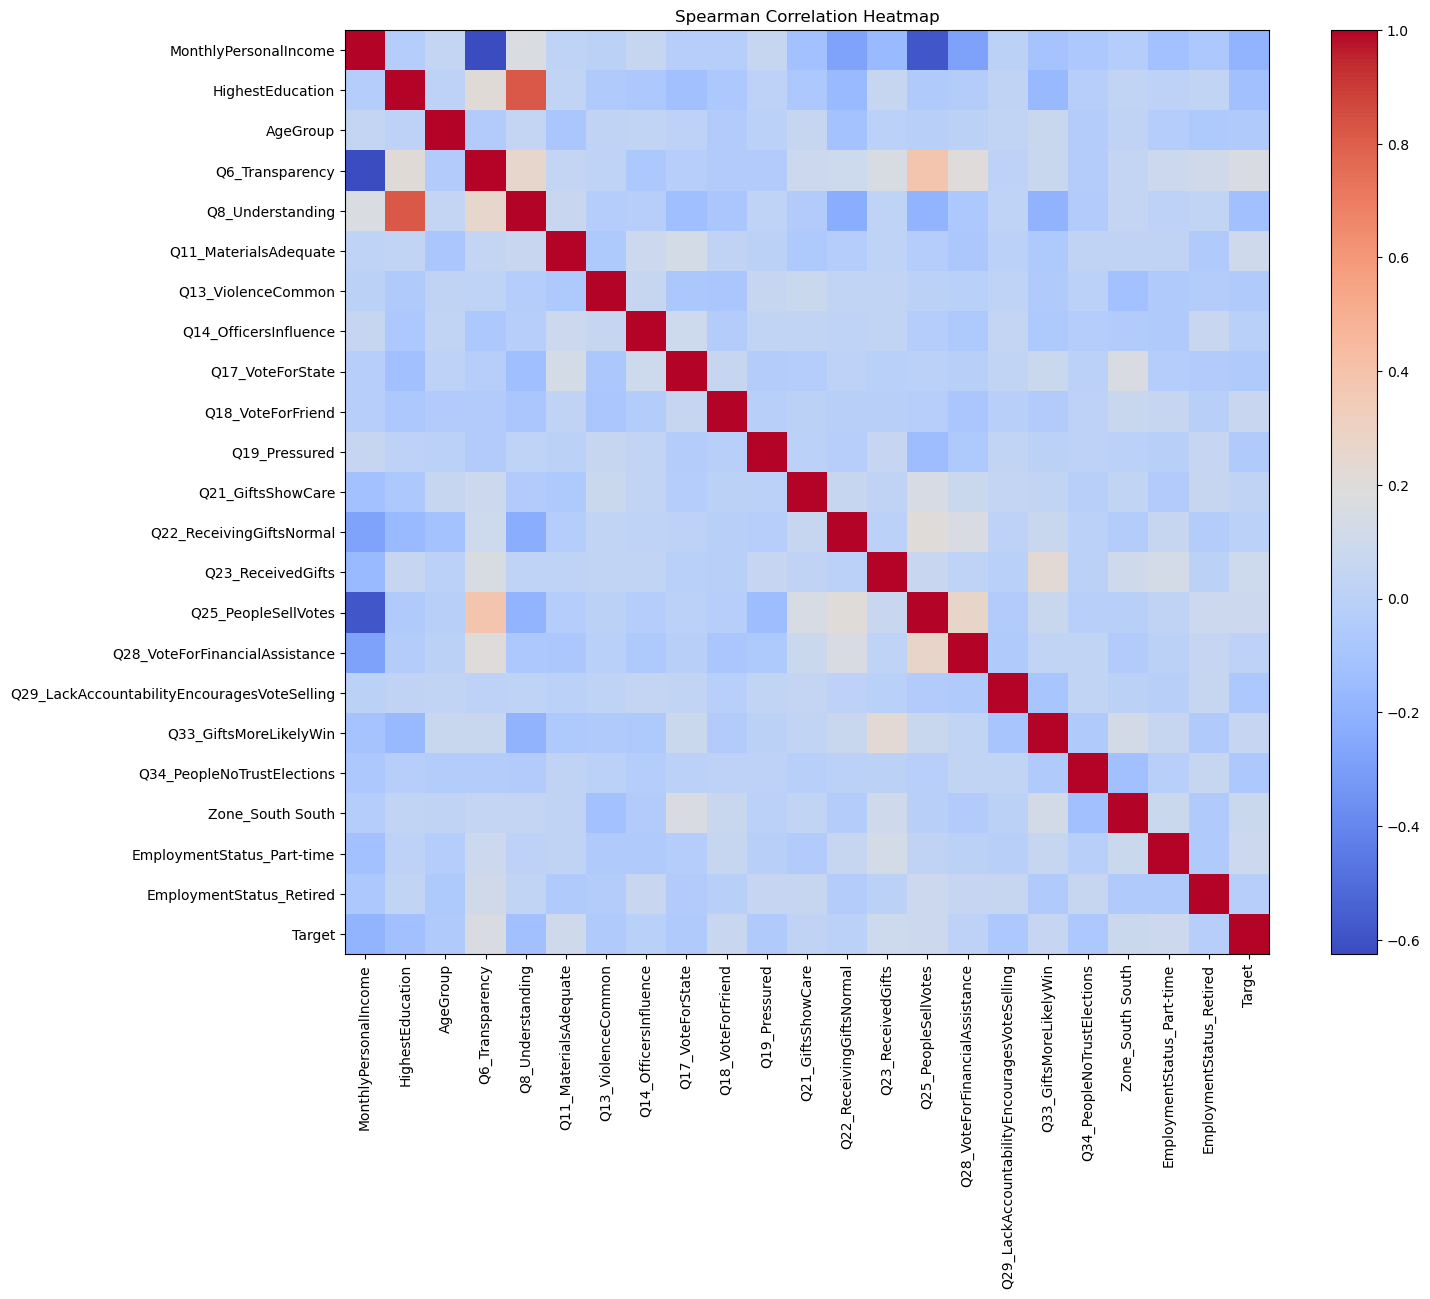

In [13]:
plt.figure(figsize=(16,12))
corr = df[selected_features + ["Target"]].corr(method='spearman')

plt.imshow(corr, cmap='coolwarm', interpolation='nearest')
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Spearman Correlation Heatmap")
plt.show()

In [ ]:
### split data to Train/Test Split

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)